# Reto 2 · Feature engineering

Seleccionamos y preparamos las variables que alimentarán el clustering pensando como analistas de negocio:
**¿qué distingue a un cliente de otro de cara a una oferta, un plan de mantenimiento o una campaña de fidelización?**

Todo el proceso está encapsulado en un `sklearn.Pipeline` definido en [`src/mb_features.py`](../src/mb_features.py):

```
CSV crudo ──► ClientAggregator ──► ColumnTransformer ──► matriz lista para K-Means
              (limpieza + 1 fila/cliente     (imputación · log1p · escalado)
               + features derivadas)
```

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import plot_style as ps
import mb_features as mf

ps.apply()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CSV = next(p for p in [DATA_DIR / "datos_reto_mercedes_benz_malackathon.csv",
                       ROOT / "datos_reto_mercedes_benz_malackathon.csv"] if p.exists())

In [2]:
from sklearn import set_config
set_config(display="diagram")
pipeline = mf.make_full_pipeline()
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('aggregate', ...), ('preprocess', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

## 1. Ejecución del pipeline

In [3]:
raw = mf.load_raw(CSV)
clients = pipeline.named_steps["aggregate"].fit_transform(raw)
X = pipeline.named_steps["preprocess"].fit_transform(clients)
feature_names = pipeline.named_steps["preprocess"].get_feature_names_out()
print(f"Clientes: {X.shape[0]:,} · Features del modelo: {X.shape[1]}")
X_df = pd.DataFrame(X, columns=feature_names, index=clients.index)
X_df.describe().T.round(2)

Clientes: 173,456 · Features del modelo: 12


,count,mean,std,min,25%,50%,75%,max
currently_connected_vehicles,173456.0,-0.00,1.00,-2.32,0.09,0.09,0.09,8.45
n_vehicles_history,173456.0,-0.00,1.00,-0.45,-0.45,-0.45,0.65,14.87
workshop_visits_per_vehicle,173456.0,-0.00,1.00,-1.24,-1.24,0.06,0.72,3.88
purchasing_power_per_household_eur,173456.0,-0.00,1.00,-2.31,-0.86,0.11,0.57,3.59
age_ord,173456.0,-0.00,1.00,-1.98,-0.64,0.03,0.70,1.36
tenure_years,173456.0,-0.00,1.00,-1.64,-0.77,0.10,0.63,4.15
main_vehicle_age_years,173456.0,-0.00,1.00,-1.53,-0.80,-0.13,0.68,7.25
main_segment_tier,173456.0,0.00,1.00,-1.06,-1.06,0.14,0.14,2.54
main_electrification,173456.0,0.00,1.00,-0.62,-0.62,-0.62,0.35,2.28
is_b2b,173456.0,0.01,0.07,0.00,0.00,0.00,0.00,1.00


## 2. Features derivadas creadas

| Feature derivada | Cómo se calcula | Para qué sirve |
|---|---|---|
| `main_vehicle_age_years` | (fecha de referencia 15-10-2026 − `date_of_first_registration` del vehículo principal) / 365,25 | **Antigüedad del vehículo** (sugerida en el reto): detecta clientes en ventana de recambio |
| `main_segment_tier` | `model_class` → gama 1 (compacto) · 2 (medio) · 3 (superior) · 4 (lujo/AMG GT/G/S) | Nivel de gama: proxy del ticket y del tipo de oferta |
| `main_electrification` | `engine_concept` (inferido si nulo) → 0 combustión · 1 MHEV · 2 PHEV · 3 EV | Grado de adopción eléctrica, ordinal |
| `main_is_van` | Clase V/Vito, Sprinter, Citan, X o `product_group = T` | Separa el uso profesional/familiar de furgoneta |
| `n_vehicles_history` | nº de vehículos distintos asociados al cliente (actuales + pasados) | Profundidad de la relación / flotas |
| `workshop_visits_per_vehicle` | visitas a taller en garantía sumadas / nº vehículos | Intensidad de uso de posventa, normalizada |
| `tenure_years` | `months_as_mb_customer` / 12 | Antigüedad del cliente en años (más legible) |
| `age_ord` | `age_range` → 1 (<25) … 6 (65+) | Edad como ordinal, respeta el orden natural |
| `finance_active` | `finance_leasing_status` ∈ {active_FL_only, active_FL_and_CASH} | Cliente con contrato vivo con Mercedes-Benz Financial |
| `is_b2b` | algún vehículo con `role_type = B2B` | Cliente vinculado a empresa/flota |
| `consent_count` *(perfilado)* | suma de los 3 consentimientos | Alcanzabilidad multicanal |
| `has_telemetry` *(perfilado)* | algún vehículo con datos de conducción | Cliente "conectado" |

**Vehículo principal**: para cada cliente, el vehículo **actual** matriculado más recientemente (si no tiene ninguno actual, el más reciente).
Es el que mejor representa su situación hoy.

In [4]:
clients[["main_vehicle_type", "main_model_class", "main_vehicle_age_years", "main_segment_tier",
         "main_engine_concept", "main_electrification", "main_is_van", "n_vehicles_history",
         "workshop_visits_per_vehicle", "tenure_years", "age_ord", "finance_active", "is_b2b"]].head(8)

,main_vehicle_type,main_model_class,main_vehicle_age_years,main_segment_tier,main_engine_concept,main_electrification,main_is_van,n_vehicles_history,workshop_visits_per_vehicle,tenure_years,age_ord,finance_active,is_b2b
client_id,,,,,,,,,,,,,
0000eb1785b60456d8ca6059563d61ad9ec480b63d69f616478bc9eb50510d33,GLA 200 d 4MATIC,B-/GLA-/GLB-Class,3.926078,1.0,COMBUSTION,0.0,False,1,3.0,3.833333,5,False,False
000144e39c02702f821f69beeb7036f40cf8505051050f38ea776337ef9b6f3c,C 200 d,C-Class,3.066393,2.0,COMBUSTION,0.0,False,2,2.0,3.000000,3,False,False
00017f3423e3110fffd0e920f7bc09af8be9e76afd000486fba5946417888eb5,GLE 300 d 4MATIC,GLE-/GLS-Class,0.287474,3.0,MILD_HYBRID,1.0,False,2,0.0,0.250000,4,True,False
0002237881f9c8edb669596513bd0fda1840f744be43826b88e7132d476e1a69,GLC 220 d 4MATIC,GLC-Class,2.852841,2.0,MILD_HYBRID,1.0,False,1,3.0,2.750000,6,False,False
00025c8e89802884b50161dd460faab34f9cff05781f17d62cb8167c75278383,AMG GLB 35 4MATIC,B-/GLA-/GLB-Class,2.097194,1.0,COMBUSTION,0.0,False,2,2.0,3.583333,3,True,False
0002b5f31fce7112d1dc7587db35df82ff8e78e4f9c29aad3cb967ee58d97c94,A 200,A-Class,7.318275,1.0,COMBUSTION,0.0,False,1,0.0,2.250000,2,False,False
0002d6c6dc19be6ed54b1f39f5db326646dc089d95de5b21923166efce3d2127,E 200,E-Class,5.886379,3.0,COMBUSTION,0.0,False,1,3.0,4.750000,2,False,False
0002e9b5a6b43865aeae337b57d0cedf410c84dc63147cf826529491a1e6b5f0,CLA 200,CLA-Class,7.049966,1.0,COMBUSTION,0.0,False,1,4.0,2.666667,5,False,False


## 3. Selección justificada de features

Se eligen **12 variables** que cubren las cinco dimensiones de negocio del reto. El criterio: que sean
**accionables para marketing**, con **pocos nulos** y **no redundantes** entre sí.

| # | Feature | Dimensión | Transformación | Justificación |
|---|---|---|---|---|
| 1 | `currently_connected_vehicles` | Relación | log1p + escalado | Tamaño actual de la cuenta: particular vs. multi-vehículo/flota |
| 2 | `n_vehicles_history` | Relación | log1p + escalado | Recurrencia de compra / rotación de vehículos |
| 3 | `workshop_visits_per_vehicle` | Posventa | log1p + escalado | Clave para **planes de mantenimiento** |
| 4 | `purchasing_power_per_household_eur` | Poder adquisitivo | imputar mediana + log1p + escalado | Capacidad de compra de la zona → nivel de oferta |
| 5 | `age_ord` | Demografía | escalado | Etapa vital, tono de la comunicación |
| 6 | `tenure_years` | Relación | escalado | Antigüedad → **fidelización** |
| 7 | `main_vehicle_age_years` | Vehículo | imputar mediana + escalado | Ventana de **renovación** (ofertas de vehículo) |
| 8 | `main_segment_tier` | Vehículo | escalado | Gama → nivel de oferta (upsell) |
| 9 | `main_electrification` | Vehículo | escalado | Afinidad eléctrica → campañas EQ / carga |
| 10 | `is_b2b` | Relación | binaria 0/1 | Empresa vs. particular |
| 11 | `main_is_van` | Vehículo | binaria 0/1 | Uso profesional / familiar |
| 12 | `finance_active` | Financiación | binaria 0/1 | Contrato vivo → momento de renovación del leasing |

**Variables descartadas para el modelo (y por qué):**

- `country_code` → Se usa para **perfilar**: si entra en el modelo, K-Means parte primero por país (CH/AT) y oculta los comportamientos comunes; el poder adquisitivo ya recoge la diferencia económica.
- `gender_derived` → Es **inferido**, con un 11 % de nulos; segmentar por él es poco ético y poco útil para la oferta.
- Telemetría (`trip_*`, `speed_*`, `operating_hours_total`, `fuel_consumption_average`) → **60 % nulos**; imputarlos fabricaría un cluster artificial de "valores medianos". Se usan para perfilar.
- Consentimientos → ~85-98 % los aceptan todos: casi no varían y no separan clientes. Se usan para elegir canal por segmento.
- `population`, `number_of_households`, `purchasing_power_millions_eur`, `purchasing_power_per_inhabitant_eur` → describen el **tamaño** de la zona o están muy correlacionadas (ρ>0,9) con el poder adquisitivo por hogar.
- `finance_leasing_status` completo → se resume en `finance_active` (el modelo ya tiene la antigüedad para distinguir `was_active`).
- `role`, `is_current_vehicle`, `vehicle_type`, `model_series`, `fuel_type`, `product_group` → redundantes con las features derivadas.

In [5]:
# Redundancia comprobada: correlaciones entre variables de poder adquisitivo / zona
pp = ["purchasing_power_per_household_eur", "purchasing_power_per_inhabitant_eur",
      "purchasing_power_millions_eur", "population", "number_of_households"]
clients[pp].corr(method="spearman").round(2)

,purchasing_power_per_household_eur,purchasing_power_per_inhabitant_eur,purchasing_power_millions_eur,population,number_of_households
purchasing_power_per_household_eur,1.00,0.96,-0.08,-0.28,-0.29
purchasing_power_per_inhabitant_eur,0.96,1.00,0.05,-0.16,-0.16
purchasing_power_millions_eur,-0.08,0.05,1.00,0.97,0.97
population,-0.28,-0.16,0.97,1.00,1.00
number_of_households,-0.29,-0.16,0.97,1.00,1.00


## 4. Tratamiento de variables numéricas y categóricas

- **Imputación**: mediana para numéricas (robusta a colas largas); moda para binarias. Solo afecta a `purchasing_power_per_household_eur` (≈9 % de clientes) y `main_vehicle_age_years` (<1 %).
- **log1p** en las variables de conteo y dinero con cola larga a la derecha (vehículos, visitas, poder adquisitivo): sin él, unos pocos clientes de flota con 20 coches dominarían las distancias euclídeas.
- **StandardScaler** en numéricas y ordinales: K-Means usa distancia euclídea, así que todas deben estar en la misma escala.
- **Categóricas**: las ordinales (edad, gama, electrificación) se codifican como **enteros ordenados**, conservando el orden natural con 1 sola columna (one-hot crearía 6+4+4 columnas dispersas). Las nominales con información relevante se reducen a **binarias 0/1** (`is_b2b`, `main_is_van`, `finance_active`), que se dejan **sin estandarizar**: estandarizar una binaria rara (B2B ≈ 0,6 %) la convertiría en valores de hasta ≈13 y dominaría la distancia.

El efecto del log1p se ve claramente en las distribuciones antes y después:

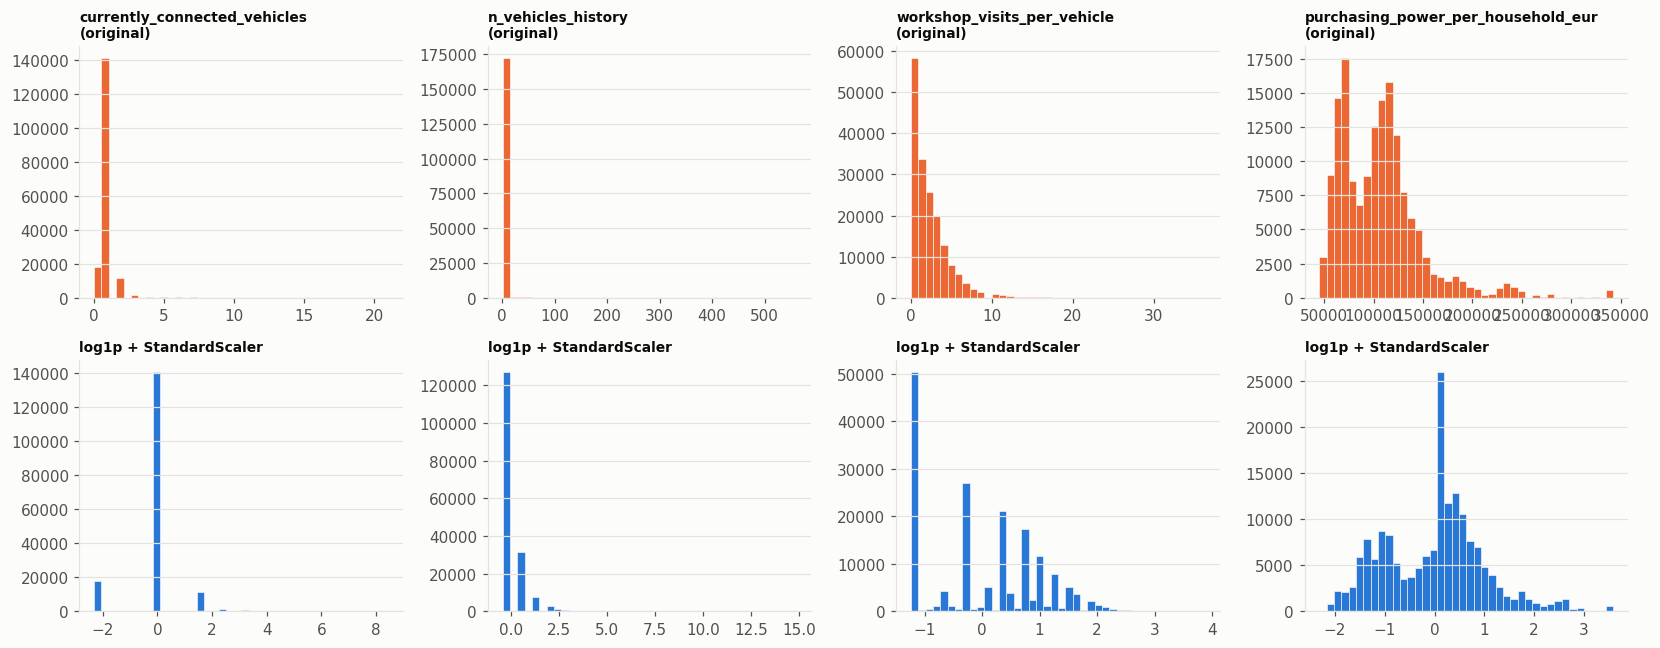

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for j, c in enumerate(mf.LOG_FEATURES):
    axes[0, j].hist(clients[c].dropna(), bins=40, color=ps.SERIES[1], edgecolor="#fcfcfb", lw=0.4)
    axes[0, j].set_title(f"{c}\n(original)", fontsize=9)
    axes[1, j].hist(X_df[c], bins=40, color=ps.SERIES[0], edgecolor="#fcfcfb", lw=0.4)
    axes[1, j].set_title("log1p + StandardScaler", fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / "02_transformaciones.png"); plt.show()

In [7]:
# Comprobaciones de la matriz final
print("Nulos en X:", int(np.isnan(X).sum()))
print("Medias (deberían ser ~0 en numéricas):"); print(X_df[mf.LOG_FEATURES + mf.NUM_FEATURES].mean().round(3).to_dict())
print("Desv. típica (≈1):"); print(X_df[mf.LOG_FEATURES + mf.NUM_FEATURES].std().round(3).to_dict())

Nulos en X: 0
Medias (deberían ser ~0 en numéricas):
{'currently_connected_vehicles': -0.0, 'n_vehicles_history': -0.0, 'workshop_visits_per_vehicle': -0.0, 'purchasing_power_per_household_eur': -0.0, 'age_ord': -0.0, 'tenure_years': -0.0, 'main_vehicle_age_years': -0.0, 'main_segment_tier': 0.0, 'main_electrification': 0.0}
Desv. típica (≈1):
{'currently_connected_vehicles': 1.0, 'n_vehicles_history': 1.0, 'workshop_visits_per_vehicle': 1.0, 'purchasing_power_per_household_eur': 1.0, 'age_ord': 1.0, 'tenure_years': 1.0, 'main_vehicle_age_years': 1.0, 'main_segment_tier': 1.0, 'main_electrification': 1.0}


## 5. Guardado para los siguientes notebooks

In [8]:
import joblib
DATA_DIR.mkdir(exist_ok=True)
clients.to_pickle(DATA_DIR / "clients.pkl")
X_df.to_pickle(DATA_DIR / "X_model.pkl")
joblib.dump(pipeline, DATA_DIR / "pipeline.joblib")
print("Guardado en", DATA_DIR)

Guardado en C:\Users\mario\Desktop\malakathon\data
